In [27]:
# autoreload the modules so that changes are reflected without restarting the kernel
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
# These files contain the functions for simulating interferometry and plotting the results.
from vanCittertZernike import make_uv_coverage, read_image_as_map, make_uv_data, point_source_map
import antenna_examples
import visibility_plots
import clean


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


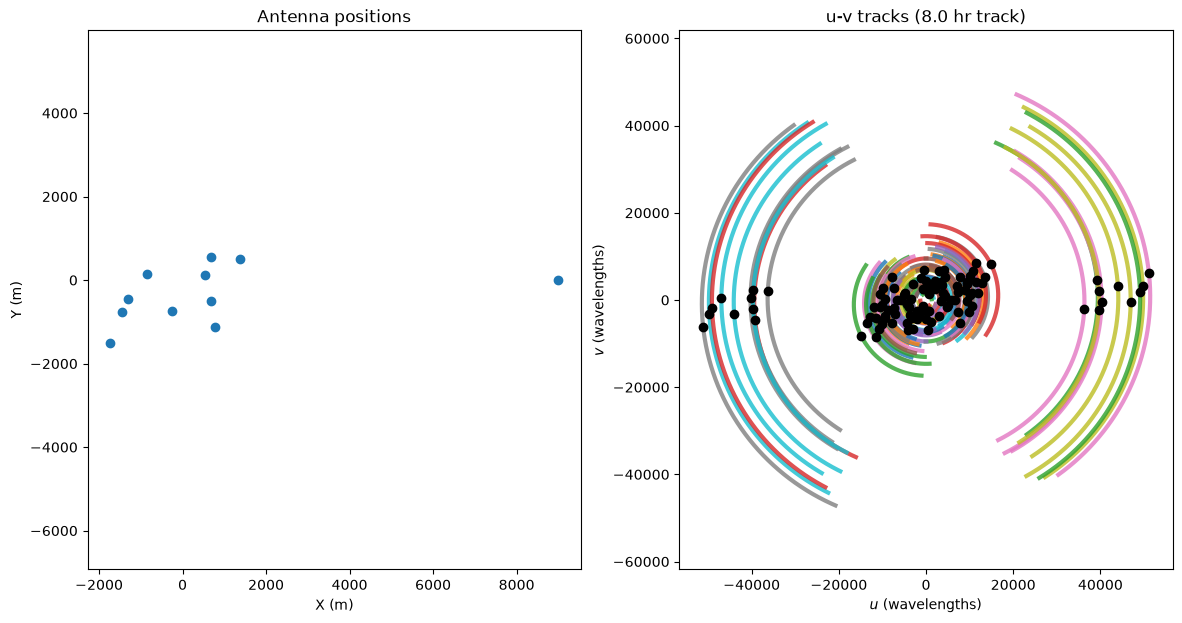

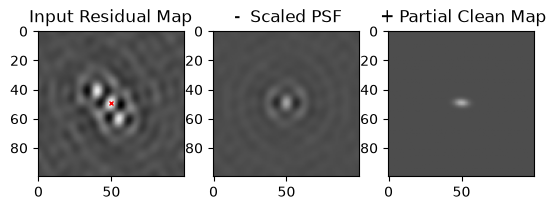

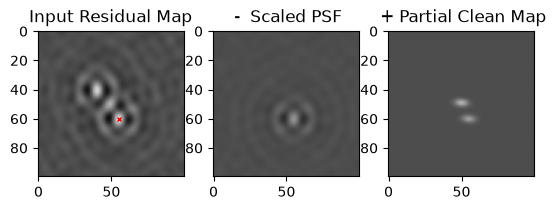

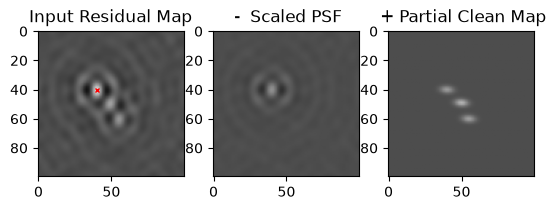

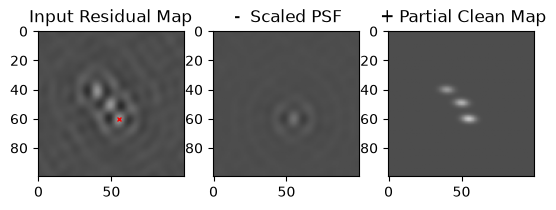

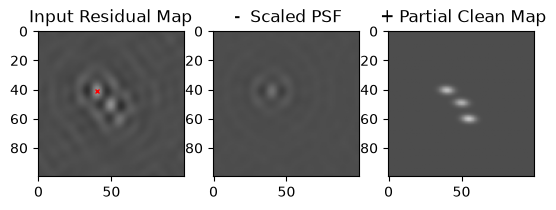

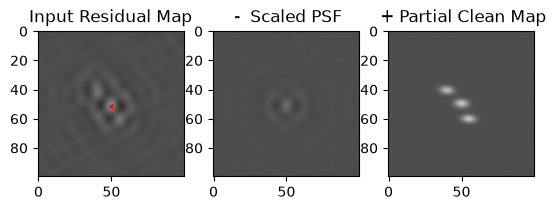

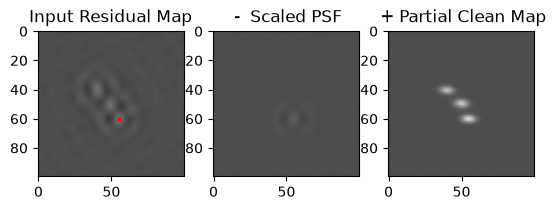

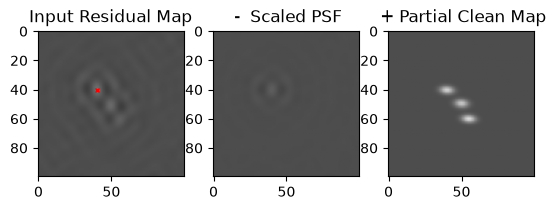

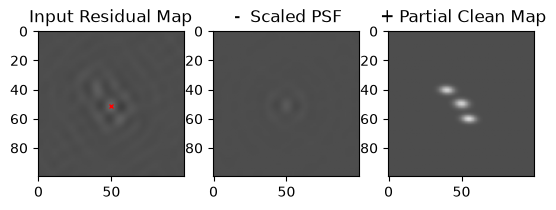

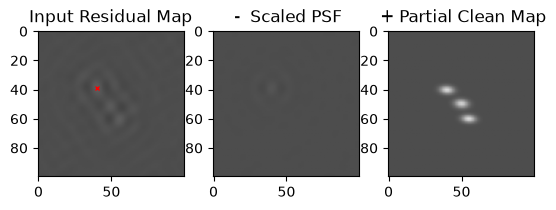

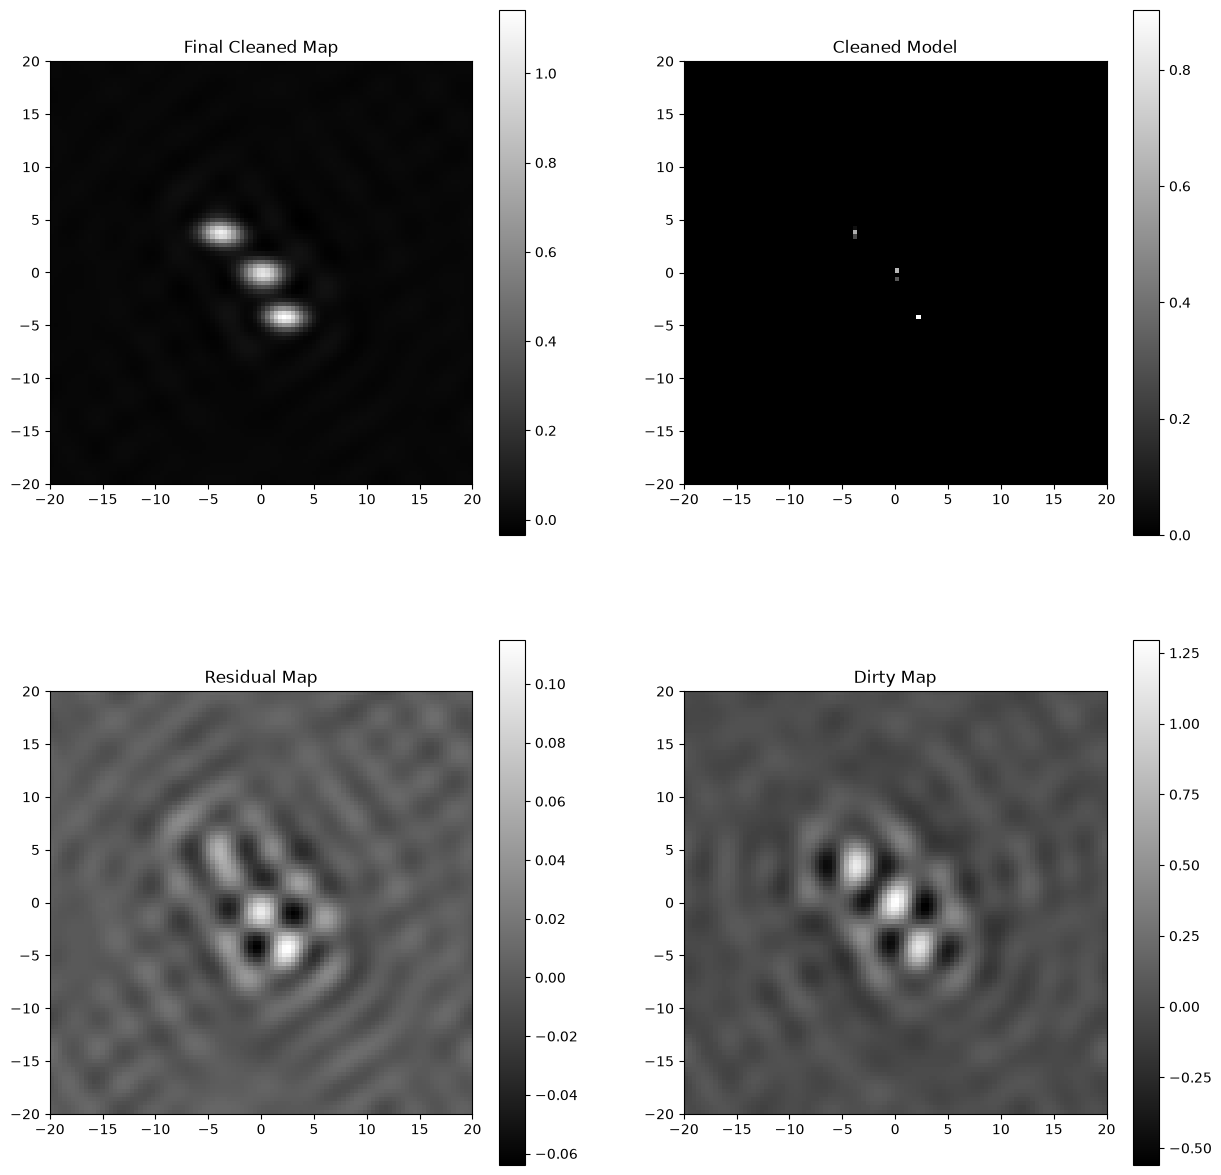

In [31]:
sky_brightness_map, pixel_scale = point_source_map(image_size=40.0 * u.arcsec, npix=100,
                                                   source_positions=[(0, 0), (5, 10), (-10, -10)], source_flux=1.0 * u.Jy)
                   

image_halfwidth=(pixel_scale*sky_brightness_map.shape[0]*u.rad).to(u.arcsec).value/2
antenna1 = antenna_examples.gaussian_cloud(nant=10, dispersion=1000*u.m)
antenna2 = [[9000,0,0]]
#antenna2 = antenna_examples.gaussian_cloud(nant=5, dispersion=3000*u.m)

antenna = np.append(antenna1, antenna2, axis=0)
tspan=12
lat=50
dec=50
weighting='uniform'
#antenna = antenna_examples.vla(config='B')
#antenna = antenna_examples.gaussian_cloud(nant=6, dispersion=400*u.m, seed=0x3606A562)

dec=80
lat=50
tspan=8
u_grid, v_grid, uv_tracks, baselines, w = make_uv_coverage(
        antenna_positions=antenna,
        pixel_scale=pixel_scale,
        image_width=sky_brightness_map.shape[0],
        declination=dec,
        latitude=lat,
        hour_angles=np.linspace(-tspan/2, tspan/2, 1000),
        wavelength=0.21,  # 21 cm
        plot=True,
    )

_u,_v,V_full,V_masked,mask, dirty_beam = make_uv_data(sky_brightness_map,
                                                       uv_tracks[:, :, 0], uv_tracks[:, :, 1], 
                                                       pixel_scale)



# Here we do the inverse Fourier transform to get the dirty image from the masked visibilities.
# We also normalize the dirty image and PSF by the peak of the dirty beam.
dirty_image = np.fft.fftshift(
    np.fft.ifft2(
        np.fft.ifftshift(V_masked)
    )
).real
beam_peak = np.amax(dirty_beam)


dirty_image /= beam_peak  # Normalize dirty image by the peak of the dirty beam
psf = dirty_beam / beam_peak  # Normalize PSF by the peak of the dirty beam

#visibility_plots.uv_and_dirty_image(V_full, V_masked, beam_peak, uv_tracks, antenna, _u, _v, image_halfwidth)


clean_beam_params,clean_beam=clean.fit_clean_beam(psf,fit_radius=10)


residual_map=np.copy(dirty_image)
cleaned_model=np.zeros_like(dirty_image)
clean_map=np.zeros_like(dirty_image)
vmin=np.amin(dirty_image)
vmax=np.amax(dirty_image)
for i in range(10):
    residual_map, cleaned_model, clean_map = clean.apply_clean_step(residual_map, psf,
                                                                     current_model=cleaned_model,
                                                                       current_clean_map=clean_map, 
                                                                       gain=0.5, 
                                                                       clean_beam_params=clean_beam_params,
                                                                       plot=True, plot_vmin=vmin, plot_vmax=vmax)


final_map = clean_map + residual_map
plt.figure(figsize=(15, 15))
plt.subplot(221)
plt.title('Final Cleaned Map')
plt.imshow(final_map, cmap='gray', extent=[-image_halfwidth, image_halfwidth, -image_halfwidth, image_halfwidth])
plt.colorbar()
plt.subplot(222)
plt.title('Cleaned Model')
plt.imshow(cleaned_model, cmap='gray', extent=[-image_halfwidth, image_halfwidth, -image_halfwidth, image_halfwidth],interpolation='nearest')
plt.colorbar()

plt.subplot(223)
plt.title('Residual Map')
plt.imshow(residual_map, cmap='gray', extent=[-image_halfwidth, image_halfwidth, -image_halfwidth, image_halfwidth])
plt.colorbar()

plt.subplot(224)
plt.title('Dirty Map')
plt.imshow(dirty_image, cmap='gray', extent=[-image_halfwidth, image_halfwidth, -image_halfwidth, image_halfwidth])

plt.colorbar()
plt.show()